# Учебное исследование с BlocksNet (Омск)

**Территория:** Россия, Омская область, город Омск  
**Версия BlocksNet:** 1.0.0.a9  
**ОС:** Windows  
**Проект:** `C:\Users\xoxom\Desktop\ТИИ`  
**Цель:** Загрузка данных, подготовка кварталов и расчёт всех показателей по примеру `examples/pipeline.ipynb`.

**Важные условия:**
- Этот ноутбук создан только для структуры. Вы будете **самостоятельно** запускать ячейки по порядку.
- Ничего скачивать и запускать автоматически не нужно.
- Для расчёта времени в пути используется **только один** готовый граф автомобильного движения (`drive`). **Интермодальный граф не строится**.
- Источник графа: **OpenStreetMap** через **osmnx** (`graph_from_place`). Способ передвижения: **автомобильный (drive)**. Время показывается **в минутах**.
- Все слои и результаты сохраняются в **GeoJSON**. Предусмотрено **повторное использование** готовых файлов.
- Зависимости берём из существующего окружения, ориентируясь на `pyproject.toml` проекта.
- **После подготовки кварталов - обязательная остановка.** Перед расчётами нужно будет уточнить доступные метрики.

## 1. Настройка окружения

Перед запуском убедитесь, что в активированном окружении установлен **blocksnet 1.0.0.a9**.

**Команды для Windows (PowerShell):**

```powershell
# Перейти в папку проекта
cd C:\Users\xoxom\Desktop\ТИИ

# Активировать виртуальное окружение (если используется .venv)
.\.venv\Scripts\Activate.ps1

# Проверить установку
pip show blocksnet
```

In [2]:
# Проверка версии blocksnet
try:
    import blocksnet
    print('blocksnet версия:', getattr(blocksnet, '__version__', 'неизвестна'))
    print('Требуется: 1.0.0.a9')
except Exception as e:
    print('Ошибка импорта blocksnet:', e)
    print('Проверьте, что blocksnet 1.0.0.a9 установлен в активированном окружении.')

blocksnet версия: 1.0.0a9
Требуется: 1.0.0.a9


## 2. Пути, папки и единые имена файлов

Весь ввод/вывод хранится в подпапках проекта.

In [3]:
import os
from pathlib import Path

# Пути
PROJECT_ROOT = Path(r'C:\Users\xoxom\Desktop\ТИИ')
DATA_DIR = PROJECT_ROOT / 'data'
OUTPUT_DIR = PROJECT_ROOT / 'output'

# Создание папок
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Пути к файлам
BOUNDARIES_PATH = DATA_DIR / 'omsk_boundaries.geojson'
ROADS_PATH = DATA_DIR / 'omsk_roads.geojson'
RAILWAYS_PATH = DATA_DIR / 'omsk_railways.geojson'
WATER_PATH = DATA_DIR / 'omsk_water.geojson'
BLOCKS_PATH = DATA_DIR / 'omsk_blocks.geojson'
GRAPH_PATH = DATA_DIR / 'omsk_drive_graph.graphml'
ACCESS_MATRIX_PATH = OUTPUT_DIR / 'omsk_accessibility_drive_minutes.csv'
BLOCKS_IND_PATH = OUTPUT_DIR / 'omsk_blocks_with_indicators.geojson'

print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATA_DIR:', DATA_DIR)
print('OUTPUT_DIR:', OUTPUT_DIR)

PROJECT_ROOT: C:\Users\xoxom\Desktop\ТИИ
DATA_DIR: C:\Users\xoxom\Desktop\ТИИ\data
OUTPUT_DIR: C:\Users\xoxom\Desktop\ТИИ\output


## 3. Загрузка исходных данных для нарезки кварталов

Повторяем подход из `examples/pipeline.ipynb`.

- Границы: `Омск, Россия`
- Слои: дороги, железная дорога, водные объекты
- Если файл уже есть в `data/` - **загружаем из него**
- Если файла нет - загружаем из **OpenStreetMap** через `osmnx`, приводим к UTM и **сохраняем в GeoJSON**

Границы: загрузка из C:\Users\xoxom\Desktop\ТИИ\data\omsk_boundaries.geojson
CRS границ: EPSG:32643


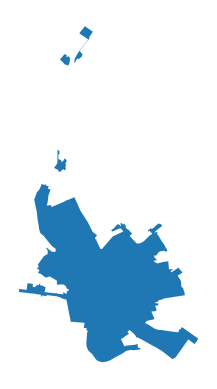

In [4]:
import geopandas as gpd
import osmnx as ox

# Границы Омска
if BOUNDARIES_PATH.exists():
    print('Границы: загрузка из', BOUNDARIES_PATH)
    boundaries = gpd.read_file(BOUNDARIES_PATH)
else:
    print('Границы: загрузка из OpenStreetMap -> Омск, Россия')
    boundaries = ox.geocode_to_gdf('Омск, Россия')
    boundaries = boundaries.to_crs(boundaries.estimate_utm_crs())
    boundaries.to_file(BOUNDARIES_PATH, driver='GeoJSON')
    print('Сохранено:', BOUNDARIES_PATH)

boundaries = boundaries.to_crs(boundaries.estimate_utm_crs())
boundaries.plot().set_axis_off()
print('CRS границ:', boundaries.crs)

In [5]:
# Теги для OSM (как в pipeline)
bc_tags = {
    'roads': {
      "highway": ["construction","crossing","living_street","motorway","motorway_link","motorway_junction","pedestrian","primary","primary_link","raceway","residential","road","secondary","secondary_link","services","tertiary","tertiary_link","track","trunk","trunk_link","turning_circle","turning_loop","unclassified"],
      "service": ["living_street", "emergency_access"]
    },
    'railways': {
      "railway": "rail"
    },
    'water': {
      'riverbank':True,
      'reservoir':True,
      'basin':True,
      'dock':True,
      'canal':True,
      'pond':True,
      'natural':['water','bay'],
      'waterway':['river','canal','ditch'],
      'landuse':'basin',
      'water': 'lake'
    }
}

# Дороги
if ROADS_PATH.exists():
    print('Дороги: загрузка из', ROADS_PATH)
    roads = gpd.read_file(ROADS_PATH)
else:
    print('Дороги: загрузка из OSM...')
    roads = ox.features_from_polygon(boundaries.to_crs('EPSG:4326').union_all(), bc_tags['roads'])
    roads = roads[roads.geom_type.isin(['LineString', 'MultiLineString'])].copy()
    roads = roads.to_crs(boundaries.crs)
    roads.to_file(ROADS_PATH, driver='GeoJSON')
    print('Сохранено:', ROADS_PATH)

# Ж/д
if RAILWAYS_PATH.exists():
    print('Ж/д: загрузка из', RAILWAYS_PATH)
    railways = gpd.read_file(RAILWAYS_PATH)
else:
    print('Ж/д: загрузка из OSM...')
    railways = ox.features_from_polygon(boundaries.to_crs('EPSG:4326').union_all(), bc_tags['railways'])
    railways = railways[railways.geom_type.isin(['LineString', 'MultiLineString'])].copy()
    railways = railways.to_crs(boundaries.crs)
    railways.to_file(RAILWAYS_PATH, driver='GeoJSON')
    print('Сохранено:', RAILWAYS_PATH)

# Вода
if WATER_PATH.exists():
    print('Вода: загрузка из', WATER_PATH)
    water = gpd.read_file(WATER_PATH)
else:
    print('Вода: загрузка из OSM...')
    water = ox.features_from_polygon(boundaries.to_crs('EPSG:4326').union_all(), bc_tags['water'])
    water = water[water.geom_type.isin(['Polygon', 'MultiPolygon', 'LineString', 'MultiLineString'])].copy()
    water = water.to_crs(boundaries.crs)
    water.to_file(WATER_PATH, driver='GeoJSON')
    print('Сохранено:', WATER_PATH)

roads = roads.to_crs(boundaries.crs)
railways = railways.to_crs(boundaries.crs)
water = water.to_crs(boundaries.crs)
print('Все слои приведены к CRS границ.')

Дороги: загрузка из C:\Users\xoxom\Desktop\ТИИ\data\omsk_roads.geojson
Ж/д: загрузка из C:\Users\xoxom\Desktop\ТИИ\data\omsk_railways.geojson
Вода: загрузка из C:\Users\xoxom\Desktop\ТИИ\data\omsk_water.geojson
Все слои приведены к CRS границ.


## 4. Подготовка кварталов (блоков)

Нарезка кварталов по логике `examples/pipeline.ipynb` с использованием `blocksnet.blocks.cutting`.

**Результат сохраняется в:** `data/omsk_blocks.geojson`

---

## СТОП: Подготовка кварталов завершена. Перед запуском расчётов спроси о доступных метриках.

**Правило:** После успешного получения слоя кварталов **НЕ ПЕРЕХОДИТЕ** к разделу 5. Сначала убедитесь, что кварталы корректны. Перед расчётом всех показателей определите, какие метрики доступны/нужны для данного исследования.

---

Кварталы: загрузка из C:\Users\xoxom\Desktop\ТИИ\data\omsk_blocks.geojson
Количество кварталов: 5643
CRS: EPSG:32643


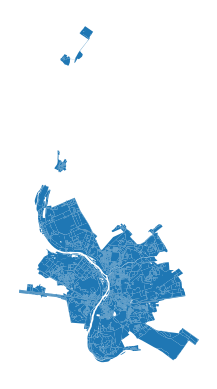

In [6]:
if BLOCKS_PATH.exists():
    print('Кварталы: загрузка из', BLOCKS_PATH)
    blocks = gpd.read_file(BLOCKS_PATH)
else:
    print('Кварталы: нарезка через blocksnet...')
    from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks
    lines, polygons = preprocess_urban_objects(roads, railways, water)
    blocks = cut_urban_blocks(boundaries, lines, polygons)
    blocks.to_file(BLOCKS_PATH, driver='GeoJSON')
    print('Сохранено:', BLOCKS_PATH)

print('Количество кварталов:', len(blocks))
print('CRS:', blocks.crs)
blocks.plot().set_axis_off()

## 5. Готовый граф и расчёт времени в пути (только один граф)

**Параметры:**
- **Источник:** OpenStreetMap через `osmnx`
- **Способ передвижения:** `drive` (автомобильный)
- **Запрос:** `graph_from_place("Омск, Россия", network_type='drive')`
- **Формат:** `graphml`, сохраняется в `data/omsk_drive_graph.graphml`
- **Расчёт:** матрица времени между кварталами по графу
- **Единицы:** **минуты**
- **Интермодальность:** **не используется**
- **Повторное использование:** если граф/матрица уже есть - загружаются из файлов

In [7]:
import networkx as nx

if GRAPH_PATH.exists():
    print('Граф: загрузка из', GRAPH_PATH)
    print('Источник: OpenStreetMap/osmnx | Способ передвижения: drive | Файл: graphml')
    G = ox.load_graphml(GRAPH_PATH)
else:
    print('Граф: не найден. Скачивание через osmnx...')
    print('Источник: OpenStreetMap/osmnx | Способ передвижения: drive')
    print('Запрос: graph_from_place("Омск, Россия", network_type="drive")')
    G = ox.graph_from_place('Омск, Россия', network_type='drive')
    ox.save_graphml(G, GRAPH_PATH)
    print('Сохранено:', GRAPH_PATH)

print('Узлов:', G.number_of_nodes())
print('Рёбер:', G.number_of_edges())

Граф: не найден. Скачивание через osmnx...
Источник: OpenStreetMap/osmnx | Способ передвижения: drive
Запрос: graph_from_place("Омск, Россия", network_type="drive")
Сохранено: C:\Users\xoxom\Desktop\ТИИ\data\omsk_drive_graph.graphml
Узлов: 7934
Рёбер: 20514


In [8]:
import numpy as np
import pandas as pd

if ACCESS_MATRIX_PATH.exists():
    print('Матрица доступности: загрузка из', ACCESS_MATRIX_PATH)
    access_matrix = pd.read_csv(ACCESS_MATRIX_PATH, index_col=0)
    print('Время в пути: минуты (повторное использование)')
else:
    print('Расчёт матрицы времени в пути по графу drive...')
    print('Источник: OpenStreetMap/osmnx | Режим: drive | Единицы: минуты')
    
    G_proj = ox.project_graph(G)
    G_proj = ox.add_edge_speeds(G_proj)
    G_proj = ox.add_edge_travel_times(G_proj)
    
    blocks_c = blocks.copy()
    blocks_c['geometry'] = blocks_c.geometry.centroid
    blocks_c = blocks_c.to_crs(G_proj.graph['crs'])
    
    orig_nodes = ox.nearest_nodes(G_proj, blocks_c.geometry.x, blocks_c.geometry.y)
    
    n = len(orig_nodes)
    access_matrix = pd.DataFrame(np.zeros((n,n)), index=blocks.index, columns=blocks.index)
    
    for i in range(n):
        lengths_sec = nx.single_source_dijkstra_path_length(G_proj, orig_nodes[i], weight='travel_time')
        for j in range(n):
            node_j = orig_nodes[j]
            if node_j in lengths_sec:
                access_matrix.iloc[i,j] = lengths_sec[node_j] / 60.0
            else:
                access_matrix.iloc[i,j] = np.nan
    
    access_matrix.to_csv(ACCESS_MATRIX_PATH)
    print('Сохранено:', ACCESS_MATRIX_PATH)
    print('Время в пути указано в минутах.')

print('Форма матрицы:', access_matrix.shape)
access_matrix.iloc[:5,:5]

Расчёт матрицы времени в пути по графу drive...
Источник: OpenStreetMap/osmnx | Режим: drive | Единицы: минуты
Сохранено: C:\Users\xoxom\Desktop\ТИИ\output\omsk_accessibility_drive_minutes.csv
Время в пути указано в минутах.
Форма матрицы: (5643, 5643)


,0,1,2,3,4
0,0.000000,1.460478,4.597001,4.592507,7.848240
1,2.907691,0.000000,4.588614,4.584119,9.775769
2,4.316734,4.797052,0.000000,1.636921,11.184813
3,4.398068,4.878385,1.636921,0.000000,11.056546
4,8.039534,8.503321,11.639844,11.145920,0.000000


## 6. Расчёт всех показателей из `examples/pipeline.ipynb`

**Задача:** Воспроизвести **все** блоки расчёта из оригинального `examples/pipeline.ipynb`, используя:
- `blocks` - слой кварталов Омска
- `access_matrix` - матрица времени в пути по графу `drive`, **в минутах**

**Рекомендации:**
- К каждому блоку расчёта добавьте короткое пояснение **простыми словами**
- Сохраняйте промежуточные результаты при необходимости
- Итоговый слой с показателями сохраните в `output/omsk_blocks_with_indicators.geojson`
- Используйте только функции/модули `blocksnet 1.0.0.a9`
- Если итоговые файлы уже есть - загружайте их для повторного использования

In [10]:
if BLOCKS_IND_PATH.exists():
    print('Итоговый слой с показателями: загрузка из', BLOCKS_IND_PATH)
    blocks_res = gpd.read_file(BLOCKS_IND_PATH)
    print('Форма:', blocks_res.shape)
    blocks_res.head()
else:
    print('Готового итогового файла нет.')
    print('Выполните все блоки из examples/pipeline.ipynb по порядку.')
    print('По завершении сохраните итоговый GeoDataFrame с показателями в:')
    print(' ', BLOCKS_IND_PATH)
    print('Используйте blocks и access_matrix (минуты).')

Готового итогового файла нет.
Выполните все блоки из examples/pipeline.ipynb по порядку.
По завершении сохраните итоговый GeoDataFrame с показателями в:
  C:\Users\xoxom\Desktop\ТИИ\output\omsk_blocks_with_indicators.geojson
Используйте blocks и access_matrix (минуты).


## 7. Сводка файлов и проверка

Проверка наличия всех файлов, созданных/загруженных в ходе работы.

In [ ]:
from pathlib import Path

print('=== data/ ===')
for p in sorted(DATA_DIR.glob('*')):
    print(' ', p.name)

print('\n=== output/ ===')
for p in sorted(OUTPUT_DIR.glob('*')):
    print(' ', p.name)

## 8. Инструкции по повторному запуску (Windows)

### Порядок запуска
1. **Активировать окружение**
   ```powershell
   cd C:\Users\xoxom\Desktop\ТИИ
   .\.venv\Scripts\Activate.ps1
   ```
2. **Открыть** `blocksnet_pipeline_study_omsk.ipynb` в Jupyter Lab/Notebook
3. **Запускать ячейки по порядку**, не запускать весь ноутбук одним кликом
4. **Дойти до раздела 4** - получить кварталы. **Сделать остановку** перед разделом 5 до уточнения доступных метрик
5. **После определения метрик** - запустить разделы 5-6

### Повторный запуск
- Если `data/*.geojson`, `data/*.graphml`, `output/*.csv`, `output/*.geojson` уже есть - ноутбук **загружает их**, не пересчитывает
- Граф: при отсутствии `omsk_drive_graph.graphml` будет скачан через `osmnx` по запросу `Омск, Россия`, `drive`. Можно вручную положить файл с таким же именем
- Матрица времени: считается **в минутах** по графу `drive`, только один граф, без интермодальности
- Все итоговые файлы сохраняются в **GeoJSON** для последующего создания **одной HTML-страницы** с картой и дашбордом

### Чек-лист финальной проверки
- [ ] Кварталы получены и сохранены
- [ ] Прошла остановка после раздела 4
- [ ] Граф `drive` загружен/скачан, источник и способ передвижения указаны
- [ ] Матрица доступности в **минутах** посчитана
- [ ] **Все** показатели из `pipeline.ipynb` воспроизведены
- [ ] Итоговый `omsk_blocks_with_indicators.geojson` сохранён
- [ ] Набор файлов готов для этапа HTML-дашборда